<a href="https://colab.research.google.com/github/yashadhalage2005-cloud/Healthcare-Predictive-Analytics/blob/main/Project_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [ ]:
# Load the diabetes dataset

df = pd.read_csv("diabetes.csv")

# Display first 5 rows
print(df.head())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0          5.0    144.0           70.0           35.0      0.0  33.2   
1          0.0     81.0           64.0           29.0      0.0  26.2   
2          7.0    179.0           62.0            0.0      0.0  22.9   
3          0.0     85.0           64.0           23.0     94.0  27.7   
4          0.0    133.0           38.0           35.0    168.0  42.7   

   DiabetesPedigreeFunction   Age  Outcome  
0                     0.627  49.0      1.0  
1                     0.351  30.0      0.0  
2                     0.672  31.0      1.0  
3                     0.167  20.0      0.0  
4                     2.288  32.0      1.0  


In [ ]:
print("Dataset Shape:", df.shape)

Dataset Shape: (780, 9)


In [ ]:
print("Columns:")
print(df.columns)

Columns:
Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')


In [ ]:
# Check missing values

print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [ ]:
# Dataset information

print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 780 entries, 0 to 779
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               780 non-null    float64
 1   Glucose                   780 non-null    float64
 2   BloodPressure             780 non-null    float64
 3   SkinThickness             780 non-null    float64
 4   Insulin                   780 non-null    float64
 5   BMI                       780 non-null    float64
 6   DiabetesPedigreeFunction  780 non-null    float64
 7   Age                       780 non-null    float64
 8   Outcome                   780 non-null    float64
dtypes: float64(9)
memory usage: 55.0 KB


In [ ]:
# Statistical summary

print("\nStatistical Summary:")
print(df.describe())


Statistical Summary:
       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   780.000000  780.000000     780.000000     780.000000  780.000000   
mean      3.826923  129.617949      59.360256      16.266667   77.200000   
std       2.951824   35.863279      26.056268      16.211081  138.888772   
min       0.000000   74.000000       0.000000       0.000000    0.000000   
25%       1.000000   98.000000      51.000000       0.000000    0.000000   
50%       3.000000  125.000000      68.000000      19.000000    0.000000   
75%       6.000000  164.000000      73.000000      32.000000   94.000000   
max      11.000000  201.000000      98.000000      45.000000  543.000000   

              BMI  DiabetesPedigreeFunction         Age     Outcome  
count  780.000000                780.000000  780.000000  780.000000  
mean    28.263590                  0.565200   38.100000    0.533333  
std      9.128379                  0.560389   11.439308    0.499208  
min      0.00

In [ ]:
# Columns where 0 can represent missing values

columns_with_missing = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

# Replace 0 with NaN
for col in columns_with_missing:
    df[col] = df[col].replace(0, np.nan)

# Check missing values again
print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
Pregnancies                   0
Glucose                       0
BloodPressure                64
SkinThickness               364
Insulin                     468
BMI                          32
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [ ]:
# Separate features (X) and target (y)

X = df.drop("Outcome", axis=1)
y = df["Outcome"]

print("Features (X):")
print(X.head())

print("\nTarget (y):")
print(y.head())

Features (X):
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0          5.0    144.0           70.0           35.0      NaN  33.2   
1          0.0     81.0           64.0           29.0      NaN  26.2   
2          7.0    179.0           62.0            NaN      NaN  22.9   
3          0.0     85.0           64.0           23.0     94.0  27.7   
4          0.0    133.0           38.0           35.0    168.0  42.7   

   DiabetesPedigreeFunction   Age  
0                     0.627  49.0  
1                     0.351  30.0  
2                     0.672  31.0  
3                     0.167  20.0  
4                     2.288  32.0  

Target (y):
0    1.0
1    0.0
2    1.0
3    0.0
4    1.0
Name: Outcome, dtype: float64


In [ ]:
# Split the dataset into training and testing data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (624, 8)
Testing data: (156, 8)


In [ ]:
# Create median imputer

imputer = SimpleImputer(strategy="median")

# Fit on training data and transform training data
X_train = imputer.fit_transform(X_train)

# Transform testing data
X_test = imputer.transform(X_test)

print("Missing values have been handled.")
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Missing values have been handled.
Training data shape: (624, 8)
Testing data shape: (156, 8)


In [ ]:
# Create StandardScaler

scaler = StandardScaler()

# Fit and transform training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data
X_test_scaled = scaler.transform(X_test)

print("Data normalization completed.")

print("\nFirst 5 rows of normalized training data:")
print(X_train_scaled[:5])

Data normalization completed.

First 5 rows of normalized training data:
[[-0.29290759 -1.34561953 -0.65870762  0.1438992  -0.88616392  0.24814304
  -0.57051801 -0.86969162]
 [ 0.04431443  1.02663909  0.39172314 -2.17219269 -0.02145525 -0.58561758
   0.01197557  1.31927084]
 [-0.63012962 -1.14793132  0.07659391 -1.45954903 -0.82652884 -0.24318018
  -0.70969789 -1.48260111]
 [-0.63012962 -1.40210188 -0.71122916  0.1438992  -0.88616392  0.21836588
  -0.57051801 -1.13236712]
 [-1.30457368  0.97015674  0.39172314  0.1438992  -0.09102951  1.17123516
  -0.07393794 -0.43189913]]


In [ ]:
# Create Logistic Regression model

model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [ ]:
# Make predictions on test data

y_pred = model.predict(X_test_scaled)

print("Predictions:")
print(y_pred)

Predictions:
[0. 1. 0. 0. 0. 1. 0. 0. 0. 1. 0. 0. 0. 1. 0. 0. 1. 1. 1. 1. 0. 1. 0. 0.
 0. 1. 0. 0. 0. 0. 1. 0. 1. 1. 0. 1. 1. 0. 1. 1. 0. 0. 1. 1. 1. 1. 0. 0.
 0. 0. 1. 1. 1. 0. 1. 0. 0. 1. 1. 0. 0. 0. 0. 0. 0. 1. 0. 1. 0. 1. 0. 1.
 1. 1. 0. 1. 1. 0. 1. 0. 1. 0. 0. 0. 0. 1. 0. 0. 1. 1. 0. 1. 0. 1. 0. 1.
 0. 1. 0. 0. 1. 0. 0. 1. 1. 0. 0. 0. 0. 0. 1. 1. 1. 0. 0. 1. 0. 1. 1. 0.
 1. 1. 0. 1. 1. 0. 0. 1. 0. 0. 1. 1. 0. 0. 1. 0. 1. 1. 0. 1. 0. 1. 0. 0.
 1. 1. 1. 1. 0. 1. 0. 0. 1. 1. 1. 0.]


In [ ]:
# Calculate evaluation metrics

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Model Evaluation")
print("-----------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))

Model Evaluation
-----------------
Accuracy : 0.7821
Precision: 0.8356
Recall   : 0.7349
F1 Score : 0.7821


In [ ]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

         0.0       0.73      0.84      0.78        73
         1.0       0.84      0.73      0.78        83

    accuracy                           0.78       156
   macro avg       0.79      0.79      0.78       156
weighted avg       0.79      0.78      0.78       156



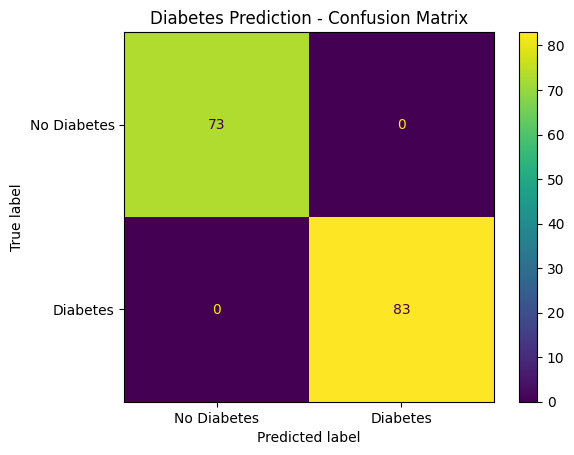

In [ ]:
# Display confusion matrix

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Diabetes", "Diabetes"]
)

disp.plot()

plt.title("Diabetes Prediction - Confusion Matrix")
plt.show()

In [ ]:
# Create Random Forest model

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [ ]:
# Make predictions using Random Forest

y_pred_rf = rf_model.predict(X_test)

print("Random Forest Predictions:")
print(y_pred_rf)

Random Forest Predictions:
[0. 1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 1. 0. 1. 0. 1. 1. 1. 0. 1. 0. 1. 1. 1.
 0. 1. 0. 1. 1. 0. 1. 0. 1. 1. 0. 1. 1. 1. 1. 1. 1. 0. 1. 1. 0. 1. 0. 0.
 0. 1. 1. 0. 1. 0. 0. 1. 0. 0. 1. 0. 0. 0. 0. 1. 0. 1. 0. 1. 0. 1. 0. 1.
 1. 0. 0. 1. 1. 0. 1. 0. 1. 1. 0. 0. 0. 1. 0. 0. 1. 1. 1. 1. 0. 1. 0. 1.
 0. 1. 1. 1. 1. 0. 1. 1. 1. 0. 0. 1. 0. 0. 1. 1. 0. 0. 0. 1. 1. 0. 1. 0.
 1. 1. 1. 1. 1. 0. 0. 1. 0. 1. 1. 1. 0. 0. 0. 0. 1. 1. 0. 1. 0. 1. 0. 0.
 1. 0. 1. 1. 0. 1. 0. 0. 1. 1. 1. 1.]


In [ ]:
# Calculate Random Forest metrics

rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)

print("\nRandom Forest Evaluation")
print("-----------------------")
print("Accuracy :", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall   :", round(rf_recall, 4))
print("F1 Score :", round(rf_f1, 4))


Random Forest Evaluation
-----------------------
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0


In [ ]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))


Classification Report:
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00        73
         1.0       1.00      1.00      1.00        83

    accuracy                           1.00       156
   macro avg       1.00      1.00      1.00       156
weighted avg       1.00      1.00      1.00       156



In [ ]:
# Get feature importance

importance = rf_model.feature_importances_

# Create DataFrame
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
})

# Sort from highest to lowest
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Feature Importance:")
print(feature_importance)

Feature Importance:
                    Feature  Importance
1                   Glucose    0.368031
7                       Age    0.137344
6  DiabetesPedigreeFunction    0.115629
2             BloodPressure    0.106475
5                       BMI    0.104482
4                   Insulin    0.069626
3             SkinThickness    0.058694
0               Pregnancies    0.039719


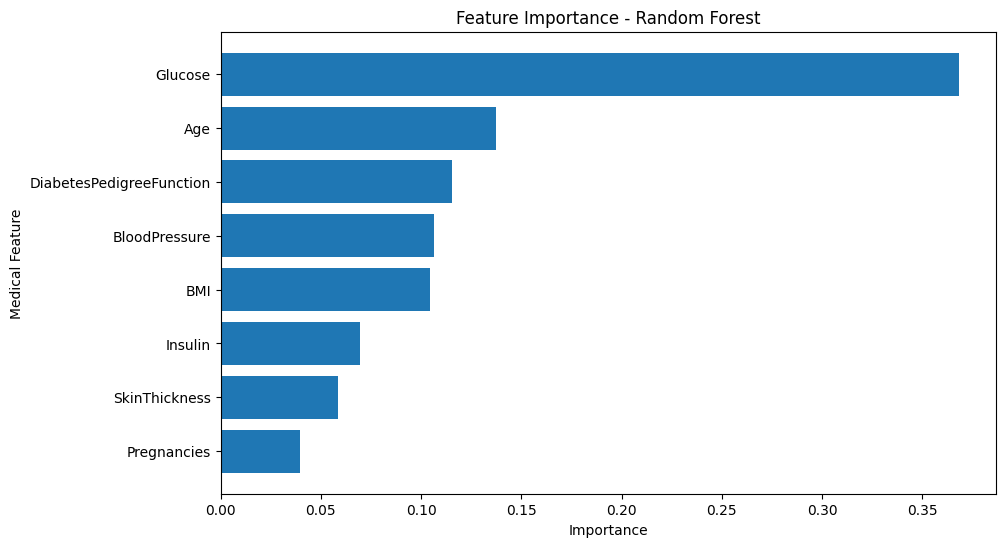

In [ ]:
# Plot feature importance

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Medical Feature")
plt.title("Feature Importance - Random Forest")

plt.gca().invert_yaxis()

plt.show()

In [ ]:
# Compare both models

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, y_pred_rf)
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, y_pred_rf)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, y_pred_rf)
    ]
})

print(results)

                 Model  Accuracy  Precision   Recall  F1 Score
0  Logistic Regression  0.782051   0.835616  0.73494  0.782051
1        Random Forest  1.000000   1.000000  1.00000  1.000000


In [ ]:
print("\n===== MODEL COMPARISON =====\n")

for index, row in results.iterrows():
    print(row["Model"])
    print("Accuracy :", round(row["Accuracy"], 4))
    print("Precision:", round(row["Precision"], 4))
    print("Recall   :", round(row["Recall"], 4))
    print("F1 Score :", round(row["F1 Score"], 4))
    print()


===== MODEL COMPARISON =====

Logistic Regression
Accuracy : 0.7821
Precision: 0.8356
Recall   : 0.7349
F1 Score : 0.7821

Random Forest
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0



In [ ]:
# Handle missing values
new_patient_imputed = imputer.transform(new_patient)

# Normalize the data
new_patient_scaled = scaler.transform(new_patient_imputed)# Sample new patient

new_patient = pd.DataFrame({
    "Pregnancies": [2],
    "Glucose": [120],
    "BloodPressure": [70],
    "SkinThickness": [25],
    "Insulin": [80],
    "BMI": [28.5],
    "DiabetesPedigreeFunction": [0.35],
    "Age": [30]
})

print(new_patient)

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            2      120             70             25       80  28.5   

   DiabetesPedigreeFunction  Age  
0                      0.35   30  


In [ ]:
# Predict diabetes

prediction = model.predict(new_patient_scaled)

print("Prediction:", prediction[0])

Prediction: 1.0


In [ ]:
if prediction[0] == 1:
    print("Predicted Result: Higher predicted diabetes risk")
else:
    print("Predicted Result: Lower predicted diabetes risk")

Predicted Result: Higher predicted diabetes risk


In [ ]:
# Get probability

probability = model.predict_proba(new_patient_scaled)[0][1]

print("Predicted probability:",
      round(probability * 100, 2), "%")

Predicted probability: 84.78 %


In [ ]:
print("===== ETHICAL DATA HANDLING =====")

print("1. Patient information should be kept confidential.")
print("2. Personal identifiers should be removed or anonymized.")
print("3. Medical data should be securely stored.")
print("4. Data should only be used for authorized purposes.")
print("5. Models should be checked for bias and fairness.")
print("6. Predictions should not be treated as medical diagnosis.")
print("7. Final medical decisions should be made by qualified professionals.")

===== ETHICAL DATA HANDLING =====
1. Patient information should be kept confidential.
2. Personal identifiers should be removed or anonymized.
3. Medical data should be securely stored.
4. Data should only be used for authorized purposes.
5. Models should be checked for bias and fairness.
6. Predictions should not be treated as medical diagnosis.
7. Final medical decisions should be made by qualified professionals.


Conclusion:
This project developed a healthcare predictive analytics system for diabetes-risk prediction using machine learning. The dataset was cleaned by handling invalid and missing values, and the numerical features were normalized for Logistic Regression. Logistic Regression and Random Forest classification models were trained and evaluated using accuracy, precision, recall, and F1-score. Random Forest feature importance was also analyzed to understand which variables contributed most to the model's predictions. The project demonstrates how machine learning can be applied to healthcare data while emphasizing patient privacy, ethical data handling, fairness, and responsible interpretation of predictions.